# Physical quantity takeoff

Count actual materials and equipment without assigning mass to virtual thermal partitions or shading context.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

`quantity_takeoff(building)` returns typed `PhysicalQuantity` records for physical layers, glazing and equipment. These records distinguish area, volume, mass and count so that downstream assessment does not have to reconstruct them from a screenshot.

Trace the quantity branch in the geometry-pipeline figure. Virtual thermal partitions have no material inventory, whereas physical slabs remain counted. Neighbouring context has a shading path into compilation and preview but no path into the target's material quantities. This is why the two invariance assertions below are meaningful.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Inspect typed quantities

PhysicalQuantity records distinguish opaque layers, glazing and equipment. Null mass for glazing is deliberately different from a measured zero mass.

### Read the code and output

A null quantity is “not supplied by this representation”, not a measured zero. Glazing may have area without an invented mass; equipment can have count without material volume. The role grouping is a useful summary, but keep item IDs and hashes for any downstream replacement or audit comparison.

Reference: [The same forms under different thermal partitions](../../docs/figures/geometry-zoning.svg). This linked documentation illustration is separate from the outputs computed below.

,item_id,element_id,role,kind,physical_sha256,area_m2,volume_m3,mass_kg,count,dataset_references
0,equipment.airflow,equipment.airflow,airflow,equipment,2674fa9eee5126d5cd8c969ea68ddddb1bf315f6f0879a...,NaN,NaN,NaN,1.0,()
1,main.horizontal.0.ground.layer.59a24339bfcadad...,main.horizontal.0.ground,ground,opaque_layer,59a24339bfcadaddfd5e35a73389535011cba8a7eaead1...,600.0,90.00,3600.0,NaN,()
2,main.horizontal.0.ground.layer.dc02d898e6d4e40...,main.horizontal.0.ground,ground,opaque_layer,dc02d898e6d4e40c4f10790a2fd9ea1f29c7424959d406...,600.0,120.00,276000.0,NaN,()
3,main.horizontal.2.8.intermediate_floor.layer.d...,main.horizontal.2.8.intermediate_floor,intermediate_floor,opaque_layer,dc02d898e6d4e40c4f10790a2fd9ea1f29c7424959d406...,600.0,120.00,276000.0,NaN,()
4,main.horizontal.5.6.intermediate_floor.layer.d...,main.horizontal.5.6.intermediate_floor,intermediate_floor,opaque_layer,dc02d898e6d4e40c4f10790a2fd9ea1f29c7424959d406...,600.0,120.00,276000.0,NaN,()
5,main.horizontal.8.4.top.layer.59a24339bfcadadd...,main.horizontal.8.4.top,top,opaque_layer,59a24339bfcadaddfd5e35a73389535011cba8a7eaead1...,600.0,90.00,3600.0,NaN,()
6,main.horizontal.8.4.top.layer.dc02d898e6d4e40c...,main.horizontal.8.4.top,top,opaque_layer,dc02d898e6d4e40c4f10790a2fd9ea1f29c7424959d406...,600.0,120.00,276000.0,NaN,()
7,main.r0.e0.floor0.main.wall.glazing,main.r0.e0.floor0.main.wall,glazing,glazing,802b8dd5eea6529a59bf7406c6373b19fc4f795b2fbd61...,16.8,NaN,NaN,NaN,()
8,main.r0.e0.floor0.main.wall.layer.59a24339bfca...,main.r0.e0.floor0.main.wall,wall,opaque_layer,59a24339bfcadaddfd5e35a73389535011cba8a7eaead1...,67.2,10.08,403.2,NaN,()
9,main.r0.e0.floor0.main.wall.layer.dc02d898e6d4...,main.r0.e0.floor0.main.wall,wall,opaque_layer,dc02d898e6d4e40c4f10790a2fd9ea1f29c7424959d406...,67.2,13.44,30912.0,NaN,()


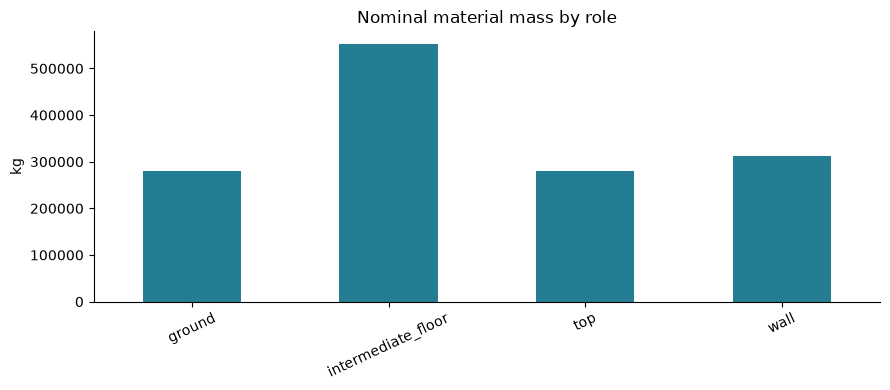

In [2]:
b = building()
quantities = quantity_takeoff(b)
assert all(isinstance(q,PhysicalQuantity) for q in quantities)
frame = table([q.model_dump() for q in quantities])
bars(frame.groupby("role").mass_kg.sum(min_count=1).dropna().to_dict(),"kg","Nominal material mass by role")

## Check zoning invariance

Perimeter/core boundaries are virtual. They should not add construction quantities when the physical building remains unchanged.

### Read the code and output

Switching to perimeter/core adds calculation boundaries rather than new material walls. The mass equality tests that distinction. It does not imply apartment zoning has the same material inventory: physical dwelling partitions and circulation are a different modelling choice.

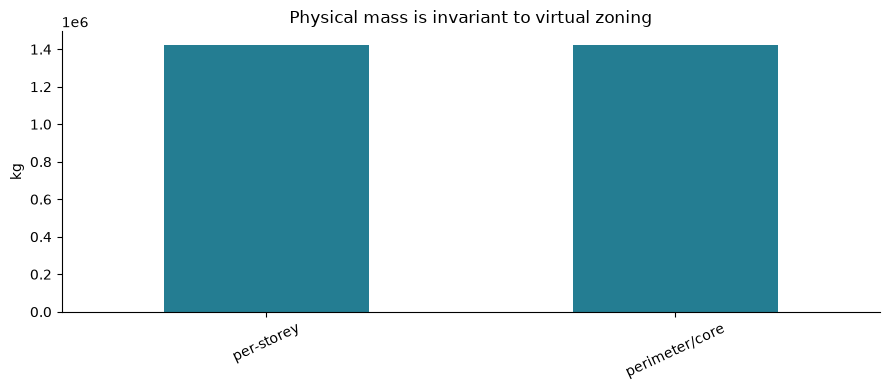

In [3]:
finer = b.updated(geometry=b.geometry.updated(zoning=ZoningSpec(mode="perimeter_core")))
other = quantity_takeoff(finer)
mass = lambda items:sum(q.mass_kg or 0 for q in items)
assert np.isclose(mass(quantities),mass(other))
bars({"per-storey":mass(quantities),"perimeter/core":mass(other)},"kg","Physical mass is invariant to virtual zoning")

## Check context exclusion

Neighbours are shading inputs rather than part of the target inventory. This distinction prevents duplicated material totals in a stock study.

### Read the code and output

Adding shading neighbours changes a simulation input while keeping target quantities unchanged. The equality assertion verifies the inventory exclusion, not an absence of shading effects on energy. For a district inventory, sum each building's own takeoff once rather than counting its context again.

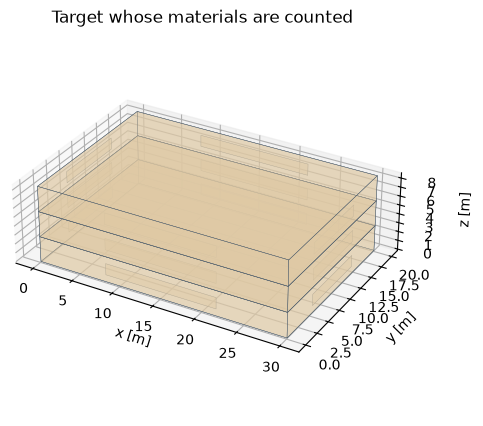

In [4]:
shaded = b.updated(context=synthetic_context(b.geometry,preset="rural",seed=3))
assert quantity_takeoff(shaded) == quantities
preview(b,"Target whose materials are counted")

## Interpretation and next experiment

Keep physical quantities for downstream assessment. EPSM Core supplies quantities and references, not automatic costs or carbon factors.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.